# Understanding grid cell area and map factors in WRF

 - Author: Lucas Bastien.
 - Copyright (c) 2025-now, Institut des Géosciences de l'Environnement, (IGE, UMR 5001), Grenoble, France.
 - License: [BSD 3-clause "New" or "Revised" license](https://spdx.org/licenses/BSD-3-Clause.html).

The relationship between real grid cell area, projected grid cell area, and map factor in WRF ouput files is not entirely intuitive. This notebook does not quite aim to entirely clarify these concepts. Rather, it aims at convincing the reader on the correct way to use map factors to convert projected surface areas into real surface areas.

We explore these topics using an arbitrary WRF output file. This file happens to use a north polar stereographic projection, but the same argument could be made with any projection.


# Dependencies and system information

In [1]:
import warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pyproj
import cartopy
import wrfpp  # Cf. https://github.com/WRF-Chem-Polar/WRF-infra

# Print system and package information
import watermark

%load_ext watermark
%watermark --machine --python --iversions

Python implementation: CPython
Python version       : 3.13.2
IPython version      : 9.0.2

Compiler    : Clang 18.1.8 
OS          : Darwin
Release     : 25.1.0
Machine     : arm64
Processor   : arm
CPU cores   : 8
Architecture: 64bit

pyproj    : 3.7.1
watermark : 2.5.0
matplotlib: 3.10.1
numpy     : 2.2.4
xarray    : 2025.3.1
cartopy   : 0.24.0



# Constants

In [2]:
# Conversion factors
m_to_km = 1e-3
m2_to_km2 = m_to_km**2

# Representation of the Earth
earth = pyproj.Geod(ellps="WGS84")

# Get grid information from WRF file

In [3]:
# Open the file
ds = xr.open_dataset("wrfout.nc").wrf

# Size of the grid
dx = ds.attrs["DX"]
dy = ds.attrs["DY"]
print("Size of the grid: %d km x %d km" % (dx * m_to_km, dy * m_to_km))

# Coordinates of the centers of the grid cells
ds.check_units("XLONG", "degree_east")
lon = ds["XLONG"].values[0, :, :]
ds.check_units("XLAT", "degree_north")
lat = ds["XLAT"].values[0, :, :]

# Coordinates of the center of the grid
lon_center = ds.attrs["CEN_LON"]
lat_center = ds.attrs["CEN_LAT"]

# Map factor
map_factor = ds["MAPFAC_M"].values[0, :, :]

# Close the file
ds.close()

Size of the grid: 100 km x 100 km


In [4]:
# Utility function(s)


def prepare_plot(projection, center=True):
    """Prepare the plot.

    Parameters
    ----------
    projection: cartopy CRS
        The projection to use for the plot.
    center: bool
        Whether to draw a red dot that represents the center of the grid.

    Returns
    -------
    Matplotlib figure, Matplotlib axes
        The Matplotlib figure and axes object of the plot.

    """
    fig = plt.figure()
    ax = fig.add_subplot(projection=projection)
    ax.coastlines(lw=0.5)
    if center:
        ax.plot(
            lon_center, lat_center, "ro", transform=cartopy.crs.PlateCarree()
        )
    return fig, ax


# Understanding the WRF grid

The WRF grid is a regular grid (squares of homogeneous size) when projected with the map projection associated with the file. The plots in this section illustrate that fact.

Below is a plot of the centers of the grid cells in the lon/lat projection map:

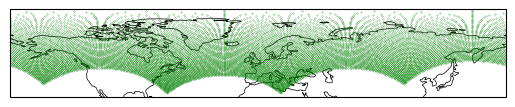

In [5]:
fig = plt.figure()
ax = fig.add_subplot(projection=cartopy.crs.PlateCarree())
ax.coastlines(lw=0.5)
_ = ax.plot(lon.flatten(), lat.flatten(), "go", markersize=0.2)

This does not like much. Let us plot the coordinates of the centers of the grid cells in the map projection used in the WRF output file instead:

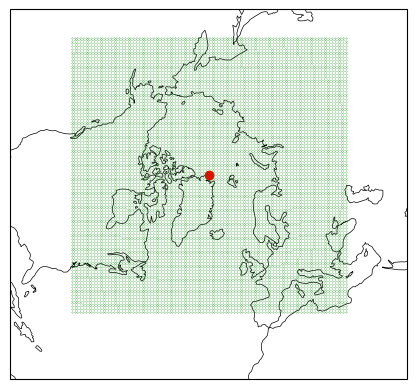

In [6]:
fig, ax = prepare_plot(ds.crs_cartopy)
_ = ax.plot(
    lon.flatten(),
    lat.flatten(),
    "go",
    markersize=0.2,
    transform=cartopy.crs.PlateCarree(),
)

Now this does look like a regular grid! Let us just zoom in a bit to have a better look

(-2668915.911276555, 1331084.0887234448)

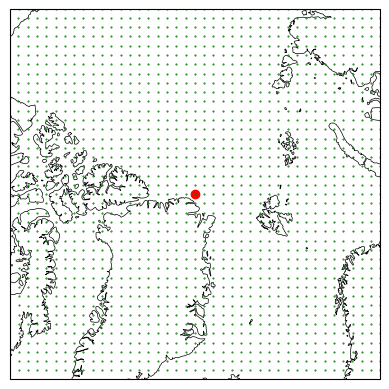

In [7]:
fig, ax = prepare_plot(ds.crs_cartopy)
ax.plot(
    lon.flatten(),
    lat.flatten(),
    "go",
    markersize=0.5,
    transform=cartopy.crs.PlateCarree(),
)
x_center, y_center = ds.ll2xy(lon_center, lat_center)
ax.set_xlim(x_center - 2000e3, x_center + 2000e3)
ax.set_ylim(y_center - 2000e3, y_center + 2000e3)


# Plot the actual area of grid cells on the Earth surface

We use `pyproj` to calculate the actual area of grid cells on the face of the Earth, accounting for curvature and all.

In [8]:
def actual_grid_cell_area(x, y):
    """Calculate actual area of grid cell centered at (x,y)."""
    xcell = [(x + dx / 2), (x + dx / 2), (x - dx / 2), (x - dx / 2)]
    ycell = [(y - dy / 2), (y + dy / 2), (y + dy / 2), (y - dy / 2)]
    return earth.polygon_area_perimeter(*ds.xy2ll(xcell, ycell))[0]


actual_grid_cell_area = np.vectorize(actual_grid_cell_area)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    area_real = actual_grid_cell_area(*ds.ll2xy(lon, lat)) * m2_to_km2

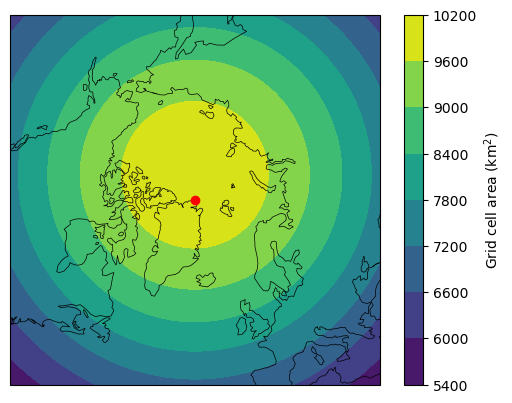

In [9]:
fig, ax = prepare_plot(ds.crs_cartopy)
plot = ax.contourf(*ds.ll2xy(lon, lat), area_real)
cb = plt.colorbar(plot, label="Grid cell area (km$^2$)")

We see that near the North Pole, the actual surface area of grid cells is close to their projected surface area. The projected surface area of grid cells is constant and equal to dx * dy = 10 000 km2. Further away from the North Pole, the area of grid cells is smaller than this value.

# Plot map factors

Here we plot the spatial distribution of map factors, which values are close to 1 near the North Pole, and increase as we move further away.

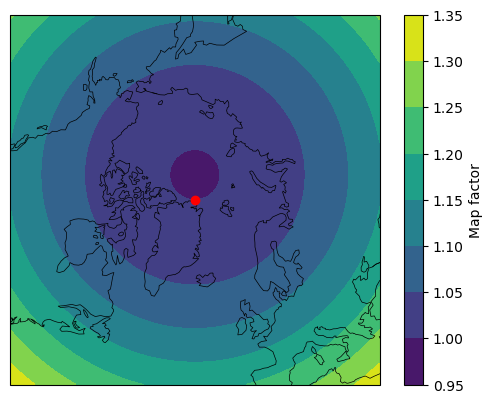

In [10]:
fig, ax = prepare_plot(ds.crs_cartopy)
plot = ax.contourf(*ds.ll2xy(lon, lat), map_factor)
cb = plt.colorbar(plot, label="Map factor")

# Recalculate grid cell area with map factor and compare to real area

Just to make sure we undersand correctly, we recalculate the actual surface area of grid cells using their projected area and map factors, and we compare these values to the results obtained with `pyproj`. The relative errors are very small (< 0.2%, cf. below). We can be confident that the folllowing holds:

actual_surface_area

= projected_surface_area / map_factor^2

= dx * dy / map_factor^2

In [11]:
area_recalc = dx * dy * m2_to_km2 / map_factor**2
diff_abs = area_recalc - area_real
diff_rel = diff_abs / area_real

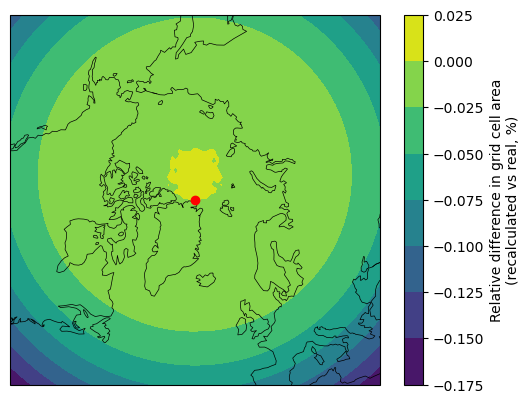

In [12]:
fig, ax = prepare_plot(ds.crs_cartopy)
plot = ax.contourf(*ds.ll2xy(lon, lat), 100 * diff_rel)
cb = plt.colorbar(
    plot,
    label="Relative difference in grid cell area\n(recalculated vs real, %)",
)